In [1]:
import torch
import torch.nn as nn
from torch.optim import Adam
import numpy as np

import tqdm 
import matplotlib.pyplot as plt
import numpy as np


In [2]:
# func = torch.nn.ReLU()
func = lambda x: x # spectral theory originally states positive definite ...

def mu(theta, r):
    # interleave imaginary part of eigenvalues (to match block diagonal)
    a_d = torch.stack((func(theta), -func(theta)), dim = -1).view(-1) # 
    b_d = torch.stack((func(r), -func(r)), dim = -1).view(-1)
    return a_d, b_d

def block_diag(fill_vals):
    # Helper function to create block-diagonal skew-symmetric matrices
    blocks = []
    for i in range(len(fill_vals)):
        block = torch.zeros((2,2))
        
        block[0,1] = fill_vals[i]
        block[1,0] = -block[0,1]
        blocks.append(block)
    return torch.block_diag(*blocks)

In [3]:
# Define parameters
N = 128  # Dimensionality of the 2N x 2N matrices (even number)

learning_rate = 0.01  # Learning rate for optimization
num_iterations = 5000  # Number of optimization steps

# Generate a learnable orthogonal transformation 
S0 = nn.Parameter(1/N*torch.randn((N, N)), requires_grad= True)

# (imaginary part of) eigenvalues
a = nn.Parameter(torch.tensor(1)*torch.rand(N//2), requires_grad=True)
b = nn.Parameter(torch.tensor(1)*torch.rand(N//2), requires_grad=True)

# starting (unit) population vector
p0 = torch.ones(N)/np.sqrt(N)

# Define optimizer
optimizer = Adam([a, b, S0], lr=learning_rate)


In [4]:
# log loss terms
l1 = []
l2 = [] 
l3 = []
l4 = [] # dette ballet på seg

counter = tqdm.trange(num_iterations)

for iteration in counter:
    optimizer.zero_grad()

    # Extract eigenvalues (imaginary parts for skew-symmetric matrices)
    mu_A, mu_B = mu(a, b)

    # form Q-matrix
    S = S0 - S0.T
    Q = torch.matrix_exp(S) # Q is orthogonal

    # Compute constraint terms
    # this is a poor sampling strategy on sphere
    dr = torch.rand((64, 1))*torch.pi/2 # random (smallish) step length
    phi  = torch.rand((64,1))*2*torch.pi # random angle

    # argument to cos
    m = torch.cos(phi)*mu_A + torch.sin(phi)*mu_B
    
    z = Q@p0 # y; using p0 is fine for commuting A,B

    yTLy = torch.sum(z**2*torch.cos(dr*m), dim=-1) # y^T L y; quadratic form

    # Define loss to optimize eigenvalues
    t1 = torch.sum(z**2*mu_A**2)
    t2 = torch.sum(z**2*mu_B**2)
    t3 = torch.sum(z**2*mu_A*mu_B)
    t4 = torch.sum(yTLy)

    # minimize correlation, second order head direction independence
    loss = (t1 - t2)**2 + t3**2 + t4

    # Backpropagation 
    loss.backward()
    optimizer.step()

    # Print progress
    if iteration % 10 == 0:
        counter.set_description(f"Iteration {iteration}, Loss: {loss.item():.3e}")
        l1.append(((t1 - t2)**2).item())
        l2.append((t3**2).item())
        l3.append(t4.item())
        l4.append(loss.item())

Iteration 4990, Loss: 3.859e+00: 100%|██████████| 5000/5000 [00:14<00:00, 355.32it/s] 


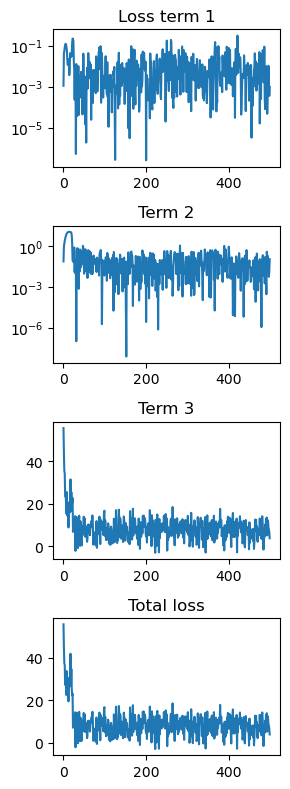

In [5]:
fig, ax = plt.subplots(4, figsize=(3, 8))
ax[0].semilogy(l1)
ax[0].set_title('Loss term 1')
ax[1].semilogy(l2)
ax[1].set_title('Term 2')
ax[2].plot(l3)
ax[2].set_title('Term 3')
ax[3].plot(l4)
ax[3].set_title('Total loss')
plt.tight_layout()

In [6]:
# Construct A, B matrices
mu_A, mu_A = mu(a, b)
 
S = S0 - S0.T
Q = torch.matrix_exp(S)

D_A = block_diag(fill_vals=a)
D_B = block_diag(fill_vals=b)

# Final matrices A and B
A = Q.T @ D_A @ Q
B = Q.T @ D_B @ Q

(-3.0477874875068665,
 3.902131140232086,
 -3.024601399898529,
 3.4748560786247253)

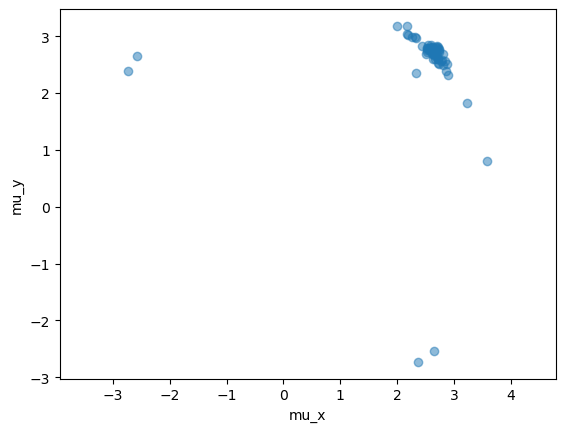

In [7]:
plt.plot(a.detach().numpy(), b.detach().numpy(), 'o', alpha = 0.5)
plt.xlabel("mu_x")
plt.ylabel("mu_y")
plt.axis('equal')

In [8]:
torch.save(A, 'A.pt')
torch.save(B, 'B.pt')